Exploratory Data Analysis (EDA) — Titanic Dataset

Dataset: Titanic Dataset (Kaggle)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

1. Membaca dataset

In [2]:
titanic = pd.read_csv('data/titanic.csv')

titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Ukuran dataset:", titanic.shape)
print("\nNama kolom:")
print(titanic.columns.tolist())

titanic.info()

Ukuran dataset: (891, 12)

Nama kolom:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


2. Memeriksa missing values dan statistik dasar

In [4]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
titanic[['Age', 'Fare', 'SibSp', 'Parch']].describe()

,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


3. Analisis sederhana berdasarkan spesies pengamatan

Dataset Titanic dikelompokkan berdasarkan jenis kelamin dan kelas tiket. Kolom Survived bernilai 0 untuk tidak selamat dan 1 untuk selamat.

In [6]:
#jumlah penumpang dan rata-rata survival berdasarkan jenis kelamin
titanic.groupby('Sex').agg(
    jumlah_penumpang=('PassengerId', 'count'),
    tingkat_selamat=('Survived', 'mean')
).reset_index()

,Sex,jumlah_penumpang,tingkat_selamat
0,female,314,0.742038
1,male,577,0.188908


In [7]:
#rata-rata tingkat keselamatan berdasarkan kelas tiket
titanic.groupby('Pclass')['Survived'].mean().sort_values(ascending=False)

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

 4. Visualisasi data

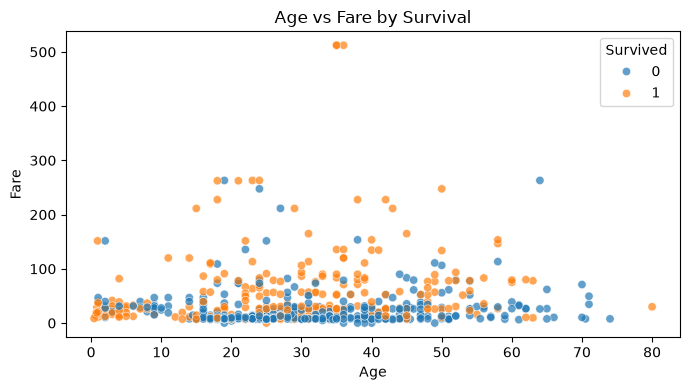

In [8]:
#scatter plot: usia dan tarif, diwarnai berdasarkan status keselamatan
plot_data = titanic.dropna(subset=['Age', 'Fare', 'Survived'])

plt.figure(figsize=(7, 4))
sns.scatterplot(data=plot_data, x='Age', y='Fare', hue='Survived', alpha=0.7)
plt.title('Age vs Fare by Survival')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.tight_layout()
plt.show()

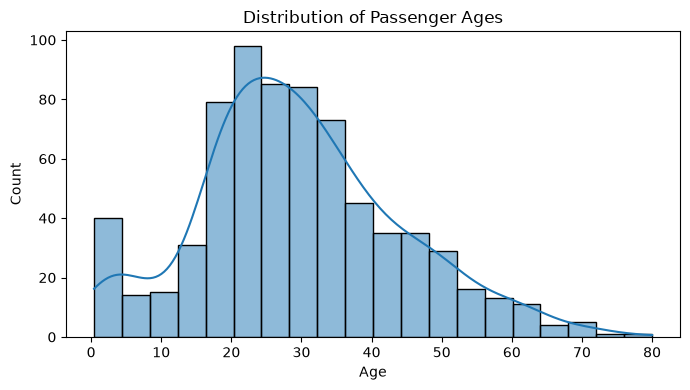

In [9]:
#histogram distribusi usia penumpang
plt.figure(figsize=(7, 4))
sns.histplot(data=titanic, x='Age', bins=20, kde=True)
plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

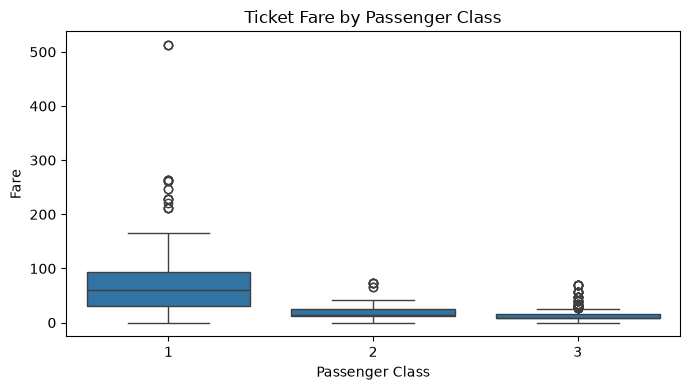

In [10]:
#boxplot tarif tiket berdasarkan kelas
plt.figure(figsize=(7, 4))
sns.boxplot(data=titanic, x='Pclass', y='Fare')
plt.title('Ticket Fare by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.tight_layout()
plt.show()